# Analyse de la dépense publique par secteur d'activité et dépendance financière des entreprises (2024–2026)

_Projet Python pour la Data Science — [BENNANI Kamil, LEMESRE Grégoire] — 2026._

## Introduction et contexte

La commande publique — qui regroupe les marchés publics, les accords-cadres et les concessions passés par l'État, les collectivités territoriales, les hôpitaux et les établissements publics — représente un levier économique majeur en France. Au-delà de sa fonction première d'approvisionnement des services publics, elle constitue un instrument de politique industrielle, de soutien au tissu productif local et de financement direct de secteurs entiers de l'économie.

Dans un contexte de débat récurrent sur l'efficacité de la dépense publique, sur l'accès des PME aux appels d'offres et sur le poids réel de l'argent public dans le modèle économique des entreprises privées, l'ouverture des Données Essentielles de la Commande Publique (DECP) offre une opportunité inédite d'observer précisément à qui profitent les marchés publics. Toutefois, les DECP seules renseignent l'objet du contrat et l'identité du titulaire, sans décrire ni le secteur économique et la taille de l'entreprise, ni son chiffre d'affaires global.

**Problématique :** _La commande publique française bénéficie-t-elle de manière disproportionnée à certains secteurs économiques et tailles d'entreprises, et quel degré de dépendance financière crée-t-elle pour les sociétés titulaires ?_

Pour répondre à cette double question, nous croisons trois référentiels publics massifs : les **DECP** (millésimes 2024 à 2026), la base **Sirene** des établissements (Insee) et les **ratios financiers** issus des comptes annuels déposés à l'**INPI / BCE**. Ce croisement permet d'analyser successivement la surreprésentation sectorielle, l'accès selon la taille d'établissement et la procédure de passation, la géographie départementale des bénéficiaires, puis le poids réel des marchés publics dans le chiffre d'affaires des entreprises.

### Sommaire

- **Introduction et contexte**

- **I. Récupération, préparation et contrôle de la qualité des données**
    - A. Présentation des sources et architecture reproductible
    - B. Diagnostic initial et nettoyage des données de la commande publique (DECP)
    - C. Préparation du répertoire Sirene et construction du référentiel sectoriel
    - D. Jointure sécurisée DECP × Sirene, contrôle qualité et dictionnaire des variables

- **II. Statistiques descriptives et visualisations : qui capte la commande publique ?**
    - A. Répartition sectorielle des montants et indice de surreprésentation
    - B. Structure et dispersion des montants annualisés par grande branche
    - C. Poids des entreprises selon la taille d'établissement
    - D. Procédures de passation et accès des différentes tailles d'entreprises
    - E. Géographie départementale de la dépense publique

- **III. Approfondissement financier : dépendance des entreprises à la commande publique (INPI / BCE)**
    - A. Agrégation par SIREN, appariement INPI et diagnostic de confidentialité
    - B. Montants publics rapportés au chiffre d'affaires : une dépendance élevée
    - C. Profils de dépendance par secteur d'activité et précautions méthodologiques

- **IV. Modélisation et pistes d'approfondissement (optionnel)**

- **Conclusion**

## I. Récupération, préparation et contrôle de la qualité des données

L'objectif de cette première partie est de collecter des jeux de données volumineux issus de sources publiques complémentaires, de documenter leur qualité initiale, de les nettoyer selon des règles explicites et de les apparier sans perte ni duplication financière. Afin de garder ce rapport lisible et modulaire, l'ensemble des traitements et des graphiques est externalisé dans des modules Python dédiés (`lire_fichiers.py`, `src/nettoyage.py`, `src/sirene_stats_desc.py` et `src/inpi_stats_desc.py`).

### A. Présentation des sources et architecture reproductible

Notre projet mobilise trois grandes sources publiques stockées au format Parquet afin d'optimiser la vitesse de lecture et l'empreinte mémoire :

| Source | Contenu principal | Volume brut observé | Rôle dans le projet |
| :--- | :--- | :--- | :--- |
| **DECP (2024–2026)** | Fichiers annuels consolidés recensant les marchés notifiés, leurs montants, durées, procédures, objets (CPV) et titulaires | **923 514 lignes** (40 colonnes) sur trois millésimes (`2024` : 263 037 ; `2025` : 331 165 ; `2026` : 329 312) | Base cœur mesurant les flux de commande publique |
| **Base Sirene (`StockEtablissement`, Insee)** | Répertoire exhaustif des établissements français : activité principale (`NAF Rev. 2`), tranche d'effectifs salariés, statut de siège social, commune, état administratif | **44 503 711 lignes** (54 colonnes) | Enrichissement sectoriel, démographique et géographique des titulaires + référentiel du tissu productif actif |
| **Données financières (INPI / BCE)** | Ratios financiers et comptes annuels des entreprises (chiffre d'affaires, marge brute, EBE, résultat net, endettement, liquidité, BFR, statut de confidentialité) | **6 813 145 lignes** (23 colonnes) pour la table des ratios | Mesure du taux de dépendance à la commande publique (`montant annualisé / chiffre d'affaires`) |

Dans une logique de reproductibilité, le code source (hébergé sur GitHub) est séparé des données volumineuses, stockées sur le stockage objet MinIO du SSP Cloud.

In [1]:
import gc
import pandas as pd

from lire_fichiers import charger_donnees
from src.nettoyage import (
    analyser_valeurs_manquantes_decp,
    inspecter_parquet,
    nettoyer_decp,
    charger_et_preparer_sirene,
    joindre_decp_et_sirene,
    construire_base_entreprises_inpi,
    diagnostiquer_appariement_inpi,
)

# URLs des fichiers Parquet stockés sur MinIO (SSP Cloud)
URL_SIRENE_ETAB = (
    "https://minio.lab.sspcloud.fr/glemesre/diffusion/"
    "stock-stocketablissement-parquet.parquet"
)
URL_RATIOS_INPI = (
    "https://minio.lab.sspcloud.fr/glemesre/diffusion/"
    "ratios_inpi_bce(1).parquet"
)

# Chargement des millésimes DECP (2024–2026)
donnees_decp = charger_donnees()
for nom_fichier, table in donnees_decp.items():
    print(f"{nom_fichier} : {table.shape[0]:,} lignes, {table.shape[1]} colonnes")

premier_millesime = next(iter(donnees_decp))
display(donnees_decp[premier_millesime].head(3))

decp-2024.parquet : 263,037 lignes, 40 colonnes
decp-2025.parquet : 331,165 lignes, 40 colonnes
decp-2026.parquet : 329,312 lignes, 40 colonnes


,id,nature,objet,codeCPV,procedure,dureeMois,dateNotification,datePublicationDonnees,montant,formePrix,...,actesSousTraitance,modificationsActesSousTraitance,modifications,dateSignature,dateDebutExecution,valeurGlobale,montantSubventionPublique,donneesExecution,concessionnaires,autoriteConcedante.id
0,202401L03,Marché,Charpente bois,45214200-2,Procédure adaptée,17,2024-02-08,2003-11-24,49066.80,Unitaire,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024/1111,Marché,LEZTROY LOT1 - FOURNITURE DE REPAS ET GOUTERS ...,55523100-3,Procédure adaptée,48,2024-07-11,2004-05-11,350000.00,Unitaire,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,202402L12,Marché de partenariat,Creation reseaux,45112500-0,Procédure adaptée,14,2024-05-14,2017-02-22,112230.57,Unitaire,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### B. Diagnostic initial et nettoyage des données de la commande publique (DECP)

Avant toute transformation, un diagnostic de complétude est mené sur l'ensemble des trois millésimes DECP (923 514 lignes) et les schémas des fichiers Parquet distants (Sirene et ratios INPI/BCE) sont vérifiés par lecture légère.

In [2]:
# Diagnostic de complétude des DECP et inspection des schémas distants
bilan_nan, colonnes_vides = analyser_valeurs_manquantes_decp(donnees_decp)
display(bilan_nan.head(15))

apercu_sirene = inspecter_parquet(URL_SIRENE_ETAB, "Sirene - StockEtablissement")
apercu_ratios = inspecter_parquet(URL_RATIOS_INPI, "Ratios financiers INPI / BCE")

del apercu_sirene, apercu_ratios
gc.collect()

Colonnes 100 % vides dans les DECP (0) : []


,nb_nan,pourcentage_nan
donneesExecution,923008,99.95
concessionnaires,922539,99.89
montantSubventionPublique,922539,99.89
dateSignature,922539,99.89
autoriteConcedante.id,922539,99.89
valeurGlobale,922539,99.89
dateDebutExecution,922539,99.89
modificationsActesSousTraitance,893438,96.74
actesSousTraitance,832652,90.16
idAccordCadre,775182,83.94



[Sirene - StockEtablissement] 44,503,711 lignes | 54 colonnes
Colonnes : ['siren', 'nic', 'siret', 'statutDiffusionEtablissement', 'dateCreationEtablissement', 'trancheEffectifsEtablissement', 'anneeEffectifsEtablissement', 'activitePrincipaleRegistreMetiersEtablissement', 'dateDernierTraitementEtablissement', 'etablissementSiege', 'nombrePeriodesEtablissement', 'complementAdresseEtablissement', 'numeroVoieEtablissement', 'indiceRepetitionEtablissement', 'dernierNumeroVoieEtablissement', 'indiceRepetitionDernierNumeroVoieEtablissement', 'typeVoieEtablissement', 'libelleVoieEtablissement', 'codePostalEtablissement', 'libelleCommuneEtablissement', 'libelleCommuneEtrangerEtablissement', 'distributionSpecialeEtablissement', 'codeCommuneEtablissement', 'codeCedexEtablissement', 'libelleCedexEtablissement', 'codePaysEtrangerEtablissement', 'libellePaysEtrangerEtablissement', 'identifiantAdresseEtablissement', 'coordonneeLambertAbscisseEtablissement', 'coordonneeLambertOrdonneeEtablissement'

29

Bien qu'aucune des 40 colonnes des DECP ne soit intégralement vide, le taux de remplissage varie fortement selon la nature des champs :

- **Champs spécifiques aux concessions et au suivi d'exécution :** quasi intégralement absents (`donneesExecution` à 99,95 % de valeurs manquantes ; `concessionnaires`, `montantSubventionPublique`, `dateSignature`, `autoriteConcedante.id`, `valeurGlobale` et `dateDebutExecution` à 99,89 %), ce qui traduit la prédominance écrasante des marchés publics classiques sur les concessions.
- **Champs facultatifs ou relatifs aux avenants :** majoritairement vides (`modificationsActesSousTraitance` à 96,74 %, `actesSousTraitance` à 90,16 %, `idAccordCadre` à 83,94 %, `modifications` à 71,69 %), tandis que les indicateurs récents restent partiellement renseignés (`marcheInnovant` à 38,67 %, `attributionAvance` à 37,95 %, `sousTraitanceDeclaree` à 31,81 %).
- **Variables structurantes du contrat :** quasiment complètes, à l'image de `dateNotification` qui ne compte que **0,11 %** de valeurs manquantes (975 lignes).

Les données brutes comportant d'anciens contrats mis à jour tardivement, des doublons de publication et des montants aberrants, nous consolidons les millésimes et appliquons la fonction `nettoyer_decp`.

In [3]:
# Consolidation, standardisation des colonnes et nettoyage des DECP
df_decp_raw = pd.concat(donnees_decp.values(), ignore_index=True)
df_decp_raw = df_decp_raw.drop(columns=colonnes_vides, errors="ignore")
df_decp_raw.columns = df_decp_raw.columns.str.replace(".", "_", regex=False)

df_decp = nettoyer_decp(df_decp_raw)

del df_decp_raw, donnees_decp
gc.collect()
print(f"DECP nettoyées prêtes pour la jointure : {len(df_decp):,} lignes")

Contrats antérieurs à 2024 écartés : 140,448
Part de lignes avec SIRET valide (14 chiffres) : 98.8%
Doublons (marché, SIRET) supprimés : 167,144
Lignes écartées pour montant aberrant (<= 100 € ou >= 500,000,000 €) : 3,732
DECP nettoyées prêtes pour la jointure : 712,959 lignes


Chaque étape de filtrage répond à un choix méthodologique explicite :

- **Filtrage temporel (`ANNEE_MIN = 2024`) :** **140 448 contrats** notifiés avant 2024 mais mis à jour tardivement dans les fichiers annuels sont écartés pour conserver une fenêtre d'étude homogène (2024–2026).
- **Aplatissement et partage des groupements :** un marché pouvant être attribué à plusieurs co-titulaires, les lignes sont aplaties au grain `(marché, titulaire)` et le montant est divisé équitablement (`montant_part = montant / nb_titulaires`).
- **Validation des identifiants SIRET :** seuls les titulaires identifiés par un SIRET normalisé à 14 chiffres sont conservés (**98,8 %** des lignes), ce qui écarte les identifiants étrangers ou mal saisis. Le **SIREN** (9 chiffres) est extrait pour les analyses au niveau entreprise.
- **Déduplication :** **167 144 doublons** portant sur le couple `(marché, SIRET)` sont supprimés pour éviter tout double comptage financier.
- **Filtrage des montants aberrants :** un plancher de **100 €** écarte les accords-cadres saisis à 1 € symbolique et un plafond de **500 millions d'euros** élimine les erreurs manifestes de saisie ; **3 732 lignes** sont ainsi exclues.
- **Annualisation :** le calcul de `montant_annualise = montant_part / dureeMois * 12` permet de comparer équitablement contrats courts et marchés pluriannuels.

À l'issue de cette étape, **712 959 lignes** propres sont prêtes pour la jointure avec Sirene.

### C. Préparation du répertoire Sirene et construction du référentiel sectoriel

Nous chargeons de manière sélective les 11 colonnes utiles de `StockEtablissement` (Insee), regroupons les codes APE (`NAF Rev. 2`) dans les **21 sections NAF officielles (`A` à `U`)**, extrayons le département d'implantation (`dep_titulaire`) et construisons le référentiel économique des établissements actifs (`ref_secteurs_sirene`).

In [ ]:
# Chargement sélectif de Sirene et construction du référentiel sectoriel actif
df_sirene, ref_secteurs_sirene = charger_et_preparer_sirene(URL_SIRENE_ETAB)

ref_affichage = ref_secteurs_sirene.sort_values("nb_etablissements_actifs", ascending=False).copy()
ref_affichage["part_pct"] = (ref_affichage["part_etablissements_sirene"] * 100).round(2)
display(ref_affichage.head(10))

Sirene nettoyé : 44,503,711 établissements uniques prêts pour la jointure
=== DF_SIRENE : 44,503,711 lignes × 11 colonnes ===


,nb_etablissements
etatAdministratifEtablissement,
F,27581924
A,16921787


,naf_section,nb_etablissements_actifs,nb_entreprises_actives,part_etablissements_sirene,part_pct
12,L - Activités immobilières,3979885,3729449,0.235193,23.52
6,G - Commerce et réparation auto,1873286,1677375,0.110703,11.07
13,"M - Activités spécialisées, scientifiques et t...",1582965,1509499,0.093546,9.35
19,S - Autres activités de services,1310738,1253758,0.077459,7.75
5,F - Construction (BTP),1028103,987764,0.060756,6.08
14,N - Services administratifs et de soutien,977605,934798,0.057772,5.78
17,Q - Santé humaine et action sociale,949788,827134,0.056128,5.61
18,"R - Arts, spectacles et loisirs",857863,839240,0.050696,5.07
0,"A - Agriculture, sylviculture et pêche",830935,813718,0.049104,4.91
8,I - Hébergement et restauration,614849,553428,0.036335,3.63


La table Sirene recense **44 503 711 établissements uniques**, répartis entre **16 921 787 établissements actifs (`A`, soit 38,0 %)** et **27 581 924 établissements fermés (`F`, soit 62,0 %)**.

Nous conservons l'ensemble du stock pour la jointure afin de ne pas perdre les marchés remportés par des établissements ayant fermé ou déménagé après la signature du contrat. En revanche, le référentiel économique `ref_secteurs_sirene` est calculé exclusivement sur les **16,92 millions d'établissements actifs**. Il montre que le tissu productif français est très concentré en nombre d'établissements sur quelques grandes branches :

1. **L - Activités immobilières** : 3 979 885 établissements actifs (**23,52 %** du total national, largement portés par les SCI) ;
2. **G - Commerce et réparation auto** : 1 873 286 établissements (**11,07 %**) ;
3. **M - Activités spécialisées, scientifiques et techniques** : 1 582 965 établissements (**9,35 %**) ;
4. **S - Autres activités de services** : 1 310 738 établissements (**7,75 %**) ;
5. **F - Construction (BTP)** : 1 028 103 établissements (**6,08 %**).

À l'opposé, des branches d'infrastructures et de réseaux comme **E - Eau, assainissement et déchets** (47 561 établissements, **0,28 %**) ou **D - Électricité, gaz, vapeur et air conditionné** (258 113 établissements, **1,53 %**) occupent une place très modeste en nombre d'établissements.

### D. Jointure sécurisée DECP × Sirene, contrôle qualité et dictionnaire des variables

Les DECP nettoyées sont enrichies par une jointure à gauche (`left join`) sur la clé `siret` avec contrainte stricte de cardinalité (`many_to_one`), garantissant mathématiquement l'absence de duplication des montants publics. La fonction `joindre_decp_et_sirene` contrôle la couverture d'appariement, sauvegarde les tables propres au format Parquet et calcule le tableau de synthèse sectorielle.

In [ ]:
# Jointure sécurisée DECP x Sirene, contrôle qualité et tableau de synthèse sectorielle
df_final, synthese = joindre_decp_et_sirene(df_decp, df_sirene, ref_secteurs_sirene)

# Libération de la mémoire vive (~44,5 M de lignes de Sirene)
del df_decp, df_sirene
gc.collect()

# Synthèse de l'agrégation par secteur
display(synthese.sort_values("montant_total_M", ascending=False).head(10))
# Jointure DEPC x Sirene
display(df_final.head(5))

Table finale (marché x titulaire)      : 712,959 lignes, 28 colonnes
Taux d'appariement Sirene (en lignes)  : 99.7%
Taux d'appariement Sirene (en montant) : 99.5%


,naf_section,nb_contrats,nb_entreprises,montant_total_M,montant_median,nb_etablissements_actifs,nb_entreprises_actives,part_etablissements_sirene,part_montant_decp,indice_surrepresentation
5,F - Construction (BTP),269631,29490,172747.946212,127396.160,1028103,987764,0.060756,0.261082,4.297209
6,G - Commerce et réparation auto,97666,10889,130350.012205,100000.000,1873286,1677375,0.110703,0.197004,1.779579
13,"M - Activités spécialisées, scientifiques et t...",126355,23236,62438.778009,64455.000,1582965,1509499,0.093546,0.094367,1.008773
10,J - Information et communication,22393,4365,60679.919023,148500.000,499910,479438,0.029542,0.091708,3.104298
14,N - Services administratifs et de soutien,47785,7125,51834.070402,121500.000,977605,934798,0.057772,0.078339,1.356008
2,C - Industrie manufacturière,50075,7374,42926.232198,106076.000,477922,443194,0.028243,0.064876,2.297079
3,"D - Électricité, gaz, vapeur et air conditionné",7741,266,30994.916133,400000.000,258113,164859,0.015253,0.046844,3.071078
16,P - Enseignement,8700,2502,25951.800790,95678.540,547231,491940,0.032339,0.039222,1.212850
4,"E - Eau, assainissement et déchets",15054,1549,24763.989213,181157.265,47561,36512,0.002811,0.037427,13.316185
7,H - Transports et entreposage,13181,2326,19496.420703,194803.290,536370,497830,0.031697,0.029466,0.929610


,id,nature,procedure,codeCPV,montant,dureeMois,dateNotification,acheteur_id,lieuExecution_code,lieuExecution_typeCode,...,etablissementSiege,activitePrincipaleEtablissement,nomenclatureActivitePrincipaleEtablissement,trancheEffectifsEtablissement,codeCommuneEtablissement,etatAdministratifEtablissement,naf_code,naf_division,naf_section,dep_titulaire
0,202401L03,Marché,Procédure adaptée,45214200-2,49066.80,17,2024-02-08,21030042200016,03120,Code postal,...,True,43.91A,NAFRev2,03,03131,A,43.91A,43,F - Construction (BTP),03
1,2024/1111,Marché,Procédure adaptée,55523100-3,350000.00,48,2024-07-11,20000017200011,74130,Code postal,...,True,56.29A,NAFRev2,21,74224,A,56.29A,56,I - Hébergement et restauration,74
2,202402L12,Marché de partenariat,Procédure adaptée,45112500-0,112230.57,14,2024-05-14,21070260100019,07210,Code postal,...,False,43.12A,NAFRev2,00,07219,F,43.12A,43,F - Construction (BTP),07
3,20242024/04,Marché,Procédure adaptée,45210000-2,44701.89,7,2024-04-18,21760067500011,76220,Code postal,...,True,23.19Z,NAFRev2,NN,14711,F,23.19Z,23,C - Industrie manufacturière,14
4,202424025L07,Marché,Appel d'offres ouvert,90919300-5,223524.00,35,2024-09-24,21570463600012,57036,Code postal,...,True,81.21Z,NAFRev2,12,57616,A,81.21Z,81,N - Services administratifs et de soutien,57


Le contrôle qualité confirme la très haute fiabilité de l'appariement :

- **Table finale (`df_final`) :** **712 959 lignes × 28 colonnes** (conservation exacte du nombre de lignes nettoyées, zéro duplication).
- **Taux d'appariement Sirene en lignes :** **99,7 %**.
- **Taux d'appariement Sirene en volume financier :** **99,5 %**.

#### Dictionnaire des variables (`df_final`)

| Famille | Variables principales | Origine & Description |
| :--- | :--- | :--- |
| **Clés & acteurs** | `id`, `siret`, `siren`, `titulaire_nom`, `acheteur_id`, `acheteur_nom` | Identifiant du marché, SIRET normalisé (14 chiffres) et SIREN (9 chiffres) du titulaire, identité de l'acheteur public |
| **Variables financières & temporelles** | `montant`, `nb_titulaires`, `montant_part`, `dureeMois`, `montant_annualise`, `dateNotification` | Montant brut, part attribuée à l'établissement (`montant / nb_titulaires`), montant ramené sur 12 mois et date de notification |
| **Nature & procédure** | `nature`, `procedure`, `codeCPV`, `cpv_division`, `lieuExecution_code`, `lieuExecution_typeCode` | Type de contrat, mode de passation (`Appel d'offres ouvert`, `Procédure adaptée`…), objet européen CPV et lieu d'exécution |
| **Profil titulaire (Sirene)** | `naf_section`, `naf_division`, `naf_code`, `trancheEffectifsEtablissement`, `etablissementSiege`, `dep_titulaire`, `etatAdministratifEtablissement` | Branche d'activité (21 sections NAF), tranche d'effectifs salariés, statut siège/agence, département et état administratif (`A`/`F`) |

## II. Statistiques descriptives et visualisations : qui capte la commande publique ?

L'analyse exploratoire porte sur les lignes valides appariées dans Sirene à montant strictement positif, représentant un volume cumulé d'environ **661,7 milliards d'euros** de marchés publics notifiés sur la période 2024–2026. Elle explore successivement la concentration sectorielle, la taille unitaire des contrats, le poids des différentes tailles d'établissements, le rôle des procédures de passation et la géographie départementale des titulaires.

In [6]:
from src.sirene_stats_desc import (
    plot_montant_par_naf,
    plot_boxplot_montant_an,
    plot_montants_taille,
    plot_montant_procedure,
    plot_procedure_taille_etablissement,
    plot_carte_montants,
)

### A. Répartition sectorielle des montants et indice de surreprésentation

Nous représentons d'abord le volume financier total attribué par section NAF sur l'ensemble des secteurs, puis confrontons la part financière captée dans les DECP à la part d'établissements actifs dans Sirene à travers l'**indice de surreprésentation** :

$$\text{Indice de surreprésentation} = \frac{\text{Part du montant total dans les DECP}}{\text{Part des établissements actifs dans Sirene}}$$

Un indice supérieur à $1$ indique que le secteur capte une part de la commande publique supérieure à son poids démographique dans le tissu productif.

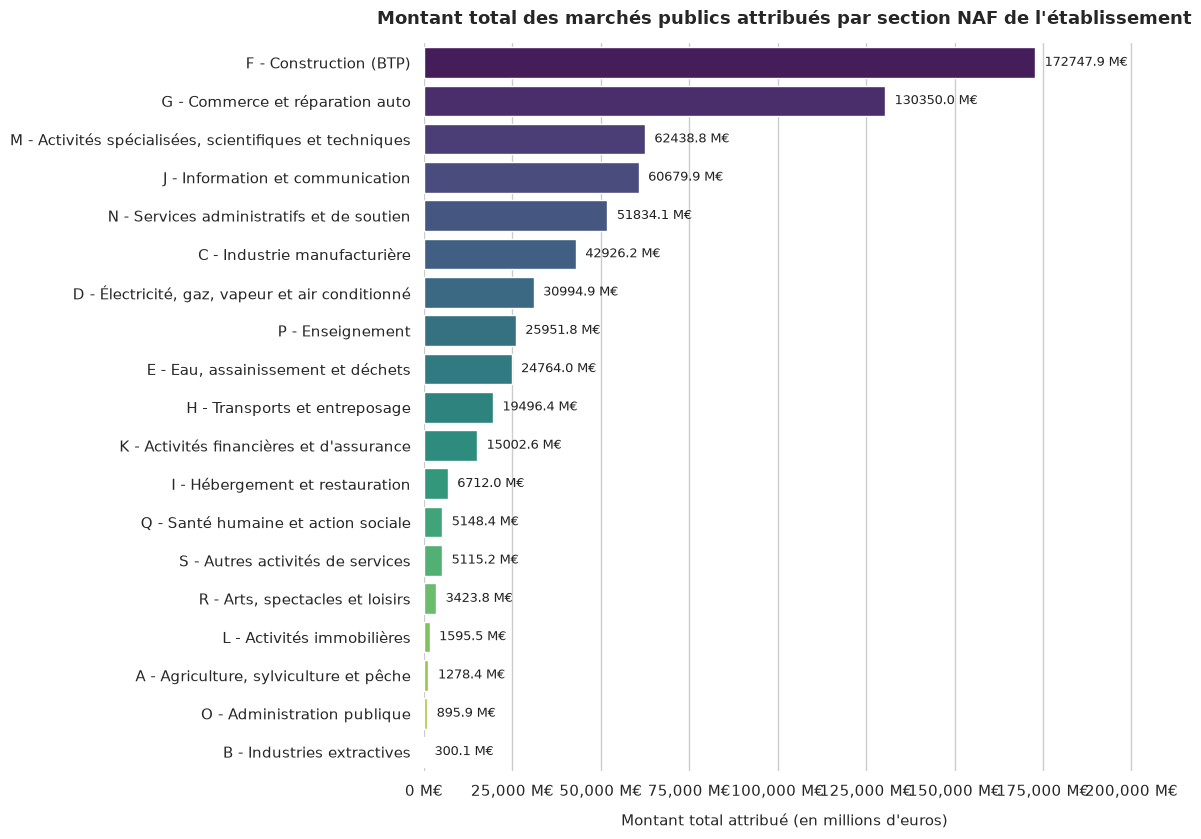

In [7]:
# Graphique 1 : Volume financier total attribué par section NAF (tous secteurs)
plot_montant_par_naf(df_final)

Le verdict est sans appel : **la commande publique bénéficie de manière fortement disproportionnée à un noyau restreint de secteurs.** Les 10 premières sections NAF concentrent **94,0 %** des montants appariés (622,2 Md€ sur ~661,7 Md€) :

| Rang | Section NAF | Montant total (M€) | Part DECP (%) | Part Sirene (%) | Indice de surreprésentation | Contrats | Entreprises | Médiane (€) |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| 1 | **F - Construction (BTP)** | 172 747,9 | 26,11 % | 6,08 % | **4,30** | 269 631 | 29 490 | 127 396 |
| 2 | **G - Commerce et réparation auto** | 130 350,0 | 19,70 % | 11,07 % | **1,78** | 97 666 | 10 889 | 100 000 |
| 3 | **M - Activités spécialisées, sc. et tech.** | 62 438,8 | 9,44 % | 9,35 % | **1,01** | 126 355 | 23 236 | 64 455 |
| 4 | **J - Information et communication** | 60 679,9 | 9,17 % | 2,95 % | **3,10** | 22 393 | 4 365 | 148 500 |
| 5 | **N - Services administratifs et de soutien** | 51 834,1 | 7,83 % | 5,78 % | **1,36** | 47 785 | 7 125 | 121 500 |
| 6 | **C - Industrie manufacturière** | 42 926,2 | 6,49 % | 2,82 % | **2,30** | 50 075 | 7 374 | 106 076 |
| 7 | **D - Électricité, gaz, vapeur et air cond.** | 30 994,9 | 4,68 % | 1,53 % | **3,07** | 7 741 | 266 | 400 000 |
| 8 | **P - Enseignement** | 25 951,8 | 3,92 % | 3,23 % | **1,21** | 8 700 | 2 502 | 95 679 |
| 9 | **E - Eau, assainissement et déchets** | 24 764,0 | 3,74 % | 0,28 % | **13,32** | 15 054 | 1 549 | 181 157 |
| 10 | **H - Transports et entreposage** | 19 496,4 | 2,95 % | 3,17 % | **0,93** | 13 181 | 2 326 | 194 803 |

Quatre enseignements majeurs se dégagent :

- **Domination massive du duo BTP–Commerce :** la **Construction (F)** capte à elle seule **172,7 Md€** (**26,11 %** de la dépense publique), devant le **Commerce (G)** avec **130,4 Md€** (**19,70 %**, achats de fournitures, matériels, équipements et véhicules). Ensemble, ces deux sections absorbent **45,8 %** des montants publics.
- **Surreprésentation record des secteurs de réseaux et d'infrastructures :** la section **E (Eau, assainissement et déchets)** atteint un indice exceptionnel de **13,32** (3,74 % des montants pour seulement 0,28 % des établissements actifs). Viennent ensuite la **Construction (4,30)**, l'**Information et communication (3,10)**, l'**Énergie (3,07)** et l'**Industrie manufacturière (2,30)**.
- **Oligopole dans l'énergie :** la section **D (Électricité, gaz, vapeur)** concentre **31,0 Md€** sur seulement **266 entreprises** distinctes.
- **Sous-représentation marquée de l'immobilier et équilibre dans certains services :** la section **L (Activités immobilières)**, 1re branche de France en nombre d'établissements actifs (23,52 %), n'apparaît même pas dans le Top 10. À l'inverse, les **Activités spécialisées, scientifiques et techniques (M)** affichent un poids financier presque exactement aligné sur leur part dans Sirene (indice de **1,01**).

### B. Structure et dispersion des montants annualisés par grande branche

Pour comparer la taille unitaire des marchés indépendamment de leur durée, nous visualisons la distribution du **montant annualisé** sur les 10 sections les plus fréquentes en nombre de contrats, sous forme de boîtes à moustaches en échelle logarithmique (valeurs extrêmes isolées masquées).

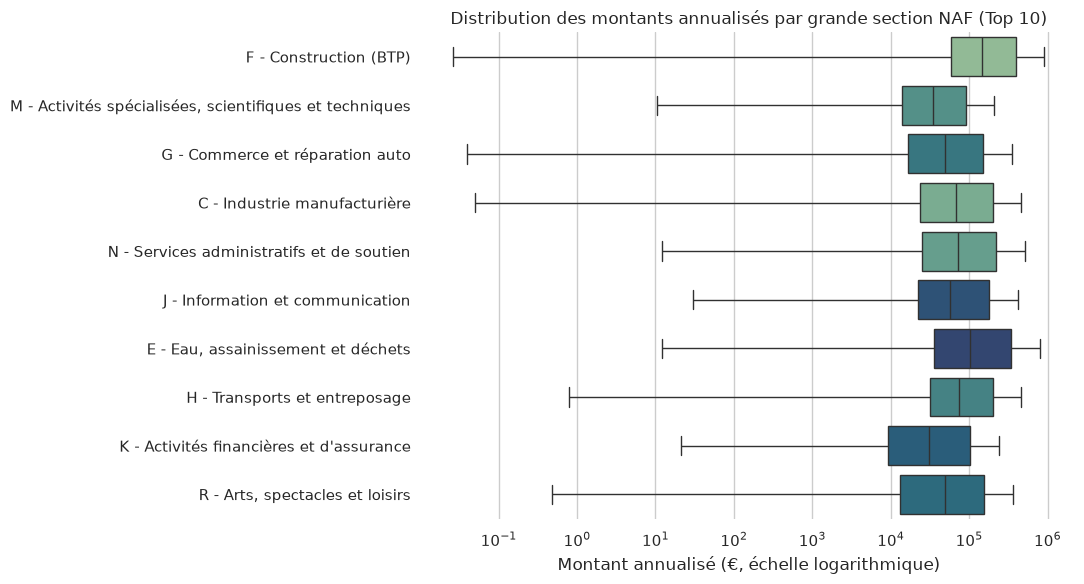

In [ ]:
# Graphique 2 : Distribution des montants annualisés (Top 10 sections NAF)
plot_boxplot_montant_an(df_final)

La lecture conjointe des distributions en échelle logarithmique et des médianes brutes oppose deux logiques économiques :

- **Les branches de « gros contrats unitaires » :** l'**Électricité et gaz (D)** domine nettement avec une médiane de **400 000 €** par marché, suivie par les **Transports et entreposage (H)** (**194 803 €**), l'**Eau, assainissement et déchets (E)** (**181 157 €**) et l'**Information et communication (J)** (**148 500 €**).
- **Les branches de « volume et de granularité » :** les **Activités spécialisées, scientifiques et techniques (M)** — ingénierie, maîtrise d'œuvre, conseil, architecture — enregistrent **126 355 contrats** (2e rang en volume de contrats) mais présentent la médiane la plus faible du Top 10 (**64 455 €**). La **Construction (F)** combine un volume contractuel massif (**269 631 contrats**, 38 % du total) et une médiane intermédiaire (**127 396 €**), reflétant la coexistence de nombreux travaux communaux d'entretien et de grands chantiers d'infrastructures.

### C. Poids des entreprises selon la taille d'établissement

Au-delà de la spécialisation sectorielle, nous examinons comment se répartit la dépense publique selon la **taille salariale de l'établissement titulaire** (regroupement des tranches d'effectifs Insee en 6 catégories standard : Micro 0–9 sal., Petite 10–49 sal., Moyenne 50–249 sal., ETI 250–4 999 sal., Grande Entreprise 5 000+ sal., et Non renseigné / 0 salarié).

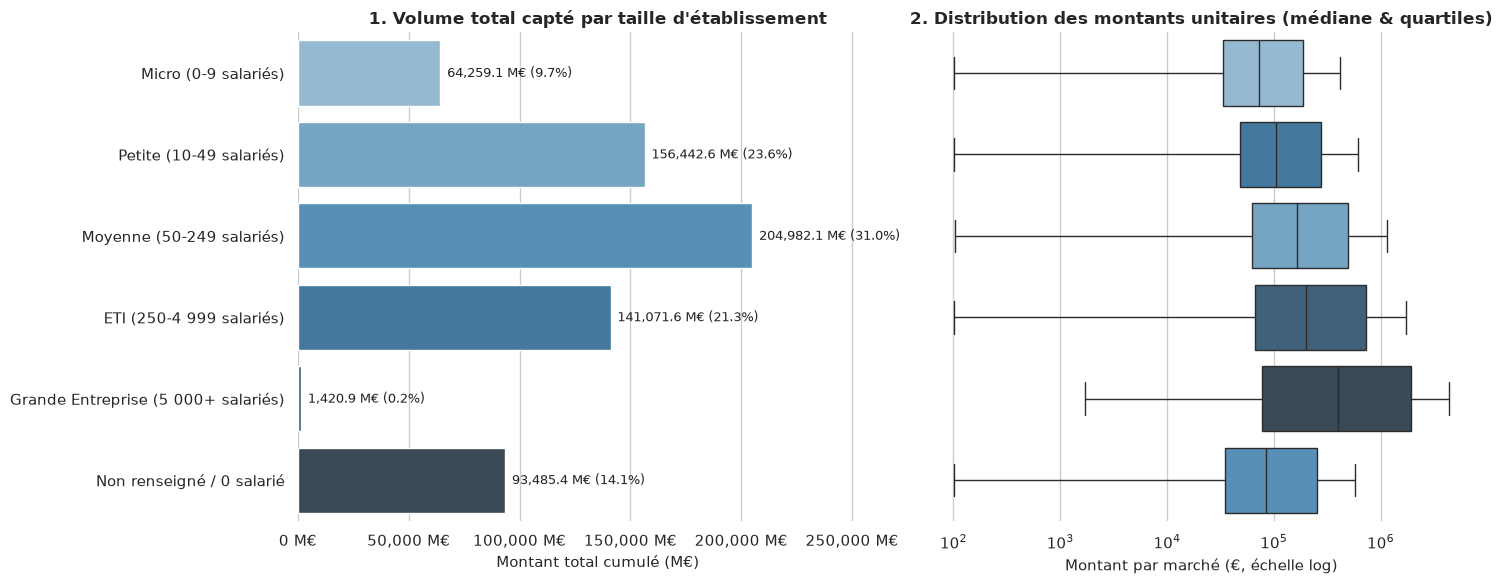

In [9]:
# Graphique 3 : Volume total capté et distribution unitaire par taille d'établissement
plot_montants_taille(df_final)

Cette analyse selon la taille d'établissement met en évidence trois constats clés :

- **Le cœur financier de la commande publique repose sur les PME (Petites et Moyennes structures) et les ETI** en volume cumulé, tandis que les établissements de plus de 5 000 salariés restent rares au grain « établissement » dans Sirene (les grands groupes répondant souvent via des filiales ou agences de taille intermédiaire).
- **Une progression nette des montants unitaires avec la taille :** la médiane et les quartiles des montants par contrat augmentent régulièrement des Micro-établissements vers les Petites, Moyennes structures et ETI, traduisant l'effet de capacité technique et financière requis pour les marchés les plus importants.
- **Un point de vigilance sur la catégorie `Non renseigné / 0 salarié` (`NN`) :** son poids rappelle que l'effectif dans Sirene peut être absent pour des établissements récents ou des holdings et qu'il reflète la taille de l'**établissement** (SIRET) plutôt que celle du groupe consolidé.

### D. Procédures de passation et accès des différentes tailles d'entreprises

Pour relier les règles juridiques de la commande publique à la structure des lauréats, nous analysons d'abord le **poids financier de chaque procédure de passation** (Graphique 4), puis croisons **procédure × taille d'établissement** en comparant la répartition en **nombre de marchés** et en **volume d'euros** (Graphique 5).

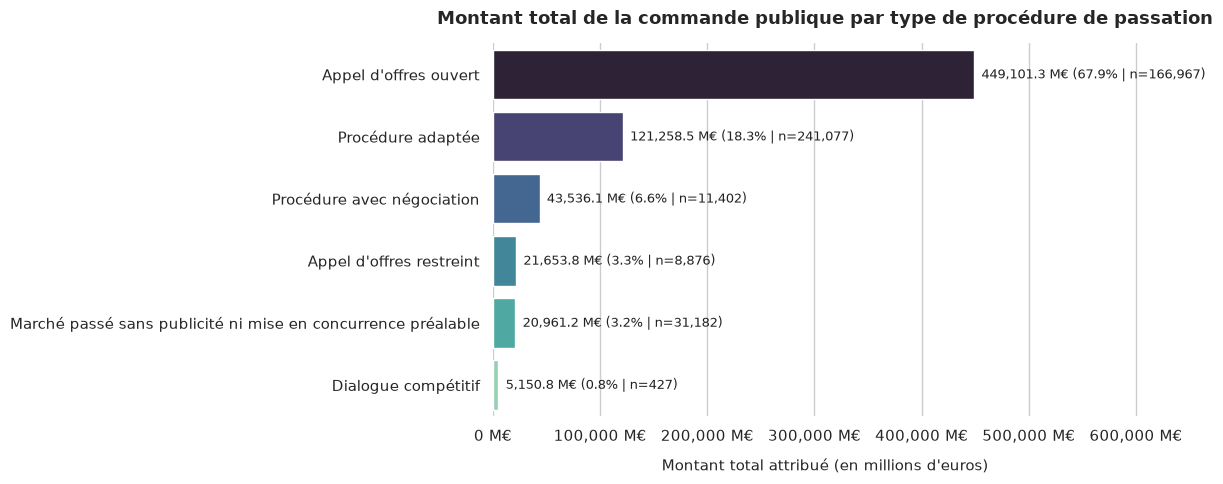

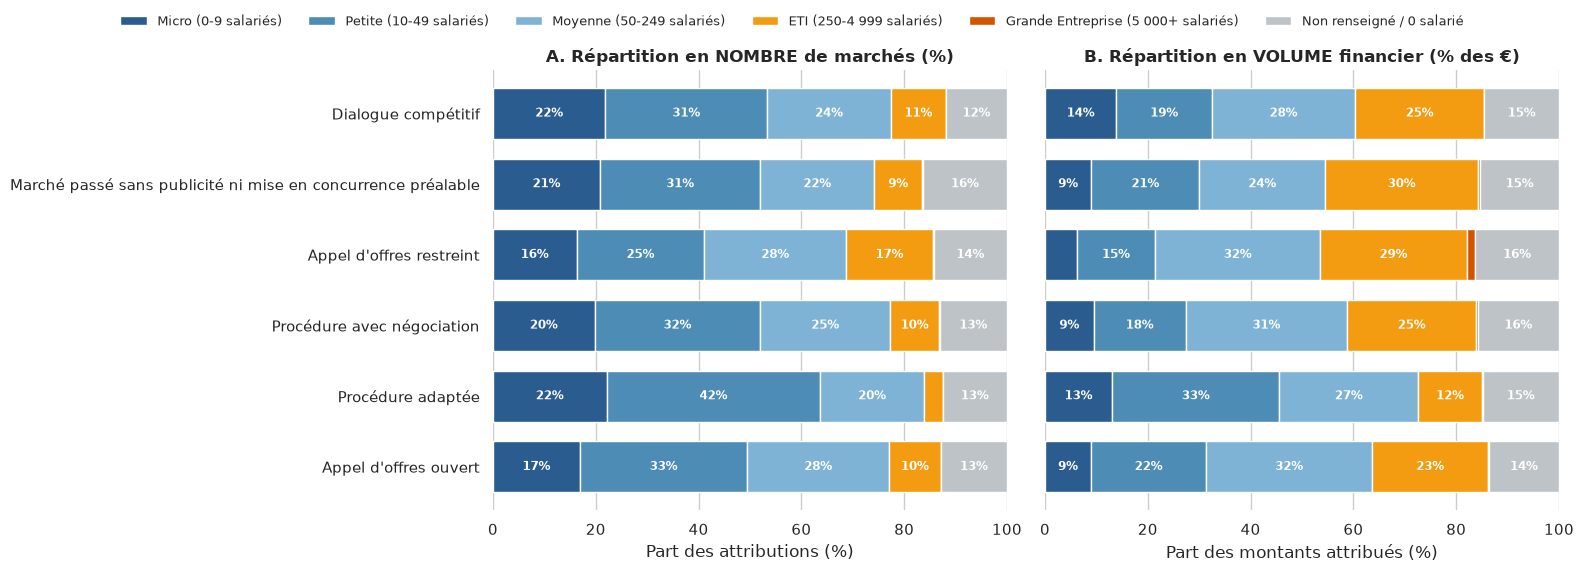

In [10]:
# Graphique 4 : Montant total attribué par type de procédure de passation
plot_montant_procedure(df_final)

# Graphique 5 : Croisement Procédure x Taille (Nombre de marchés vs Volume en euros)
plot_procedure_taille_etablissement(df_final)

L'articulation de ces deux graphiques éclaire directement le mécanisme de sélection par les seuils européens :

- **Une bipolarisation autour de deux procédures phares :** l'**Appel d'offres ouvert** (procédure formalisée au-dessus des seuils européens) et la **Procédure adaptée (MAPA)** (procédure allégée sous les seuils) concentrent l'essentiel des volumes financiers et du nombre d'attributions, loin devant les procédures avec négociation, les appels d'offres restreints et les marchés sans publicité ni mise en concurrence.
- **Un décalage systématique entre « nombre de contrats » et « volume en euros » :** la comparaison des deux panneaux du Graphique 5 montre que les **Micro et Petites structures** remportent une proportion plus élevée du *nombre* de marchés — particulièrement en procédure adaptée — mais une part plus modeste du *volume financier*, qui bascule davantage vers les **Moyennes entreprises et ETI** dans les procédures formalisées.

### E. Géographie départementale de la dépense publique

Enfin, une carte choroplèthe interactive à l'échelle départementale représente le montant total attribué (en M€) et le nombre de marchés distincts selon le **département d'implantation de l'établissement titulaire** (`dep_titulaire`).

In [11]:
# Graphique 6 : Cartographie départementale interactive des montants attribués (Plotly)
plot_carte_montants(df_final)

La cartographie révèle une forte concentration territoriale en **Île-de-France** (Paris et Hauts-de-Seine en tête) et dans les grands départements métropolitains (Rhône, Nord, Bouches-du-Rhône, Haute-Garonne, Gironde, Loire-Atlantique), par contraste avec des volumes beaucoup plus modestes dans les départements ruraux.

Cette polarisation reflète deux phénomènes superposés : le poids démographique et économique des grandes métropoles, mais aussi un **effet de domiciliation juridique** (sièges sociaux), la carte localisant l'établissement titulaire issu de Sirene (`dep_titulaire`) et non le lieu réel d'exécution des prestations (`lieuExecution_code`).

## III. Approfondissement financier : dépendance des entreprises à la commande publique (INPI / BCE)

L'analyse précédente mesurait la dépense publique du point de vue de l'acheteur public. Dans cette troisième partie, nous renversons la perspective en nous plaçant du côté des **entreprises titulaires** : quelle part de leur chiffre d'affaires annuel les marchés publics représentent-ils ?

### A. Agrégation par SIREN, appariement INPI et diagnostic de confidentialité

Les comptes annuels étant déposés au niveau de l'unité légale, la fonction `construire_base_entreprises_inpi` agrège `df_final` au niveau **SIREN (9 chiffres)** puis apparie en jointure stricte `one_to_one` le dernier bilan comptable disponible dans la base **INPI / BCE**. Nous diagnostiquons ensuite la complétude et la confidentialité des comptes.

In [15]:
# Agrégation par SIREN, jointure INPI/BCE et diagnostic de complétude/confidentialité
df_entreprise = construire_base_entreprises_inpi(df_final)

nan_summary = diagnostiquer_appariement_inpi(df_entreprise)

Entreprises uniques (SIREN) dans DECP : 101,468
Entreprises présentes dans la base INPI : 66,170 (65.2%)
Entreprises avec chiffre d'affaires non confidentiel : 66,170 (65.2%)
=== DIAGNOSTIC DES VALEURS MANQUANTES (df_entreprise) ===
                                      nb_valeurs_presentes  nb_NaN  taux_NaN_pct   type_colonne
siren                                               101468       0           0.0            str
nb_marches                                          101468       0           0.0          int64
nb_etablissements_gagnants                          101468       0           0.0          int64
montant_total                                       101468       0           0.0        float64
montant_moyen                                       101468       0           0.0        float64
montant_median                                      101468       0           0.0        float64
montant_annualise_total                             101468       0           0.0        float64

L'appariement au niveau entreprise (`df_entreprise`) apporte un éclairage précis sur la couverture des données comptables publiques :

- **Volume et taux d'appariement :** sur **101 468 entreprises uniques (SIREN)** titulaires d'au moins un marché public entre 2024 et 2026, **66 170 entreprises (65,2 %)** sont retrouvées dans la base INPI/BCE avec une date de clôture et un chiffre d'affaires renseignés. Les **35 298 entreprises non appariées (34,8 %)** correspondent aux entrepreneurs individuels, associations, organismes publics ou sociétés sans comptes déposés exploitables.
- **Impact de la confidentialité des comptes :** parmi les 66 170 entreprises appariées, **35 006** déposent des comptes intégralement **`Public`**, **27 703** optent pour **`Partiellement confidentiel`** (compte de résultat confidentiel pour les petites entreprises), **3 218** sont en **`Partiellement confidentiel (RAPCAC)`** et **243** en **`Publication simplifiee`**.
- **Conséquence sur les ratios exploitables :** si les grands postes comptables (`chiffre_d_affaires`, `ebe`, `resultat_net`, `taux_d_endettement`, `autonomie_financiere`) sont renseignés pour 65,2 % de la base, les ratios d'exploitation fins (`marge_ebe`, `poids_bfr_exploitation_sur_ca`, `rotation_des_stocks_jours`) comptent environ **65 % de valeurs manquantes** (environ **35 550 entreprises** renseignées), ce qui correspond au périmètre des sociétés à comptes non confidentiels et chiffre d'affaires strictement positif.

### B. Montants publics rapportés au chiffre d'affaires : une dépendance élevée

Sur le sous-ensemble des entreprises disposant à la fois d'un **chiffre d'affaires strictement positif** et d'un **montant annualisé de marchés positif**, nous calculons le **taux de dépendance à la commande publique** :

$$\text{Taux de dépendance (\%)} = \frac{\text{Montant annualisé total des marchés gagnés}}{\text{Chiffre d'affaires annuel}} \times 100$$

Le nuage de points en échelle log-log compare ces deux grandeurs pour les 6 principales sections NAF, avec trois droites repères à **1 %**, **10 %** et **100 %** du chiffre d'affaires.

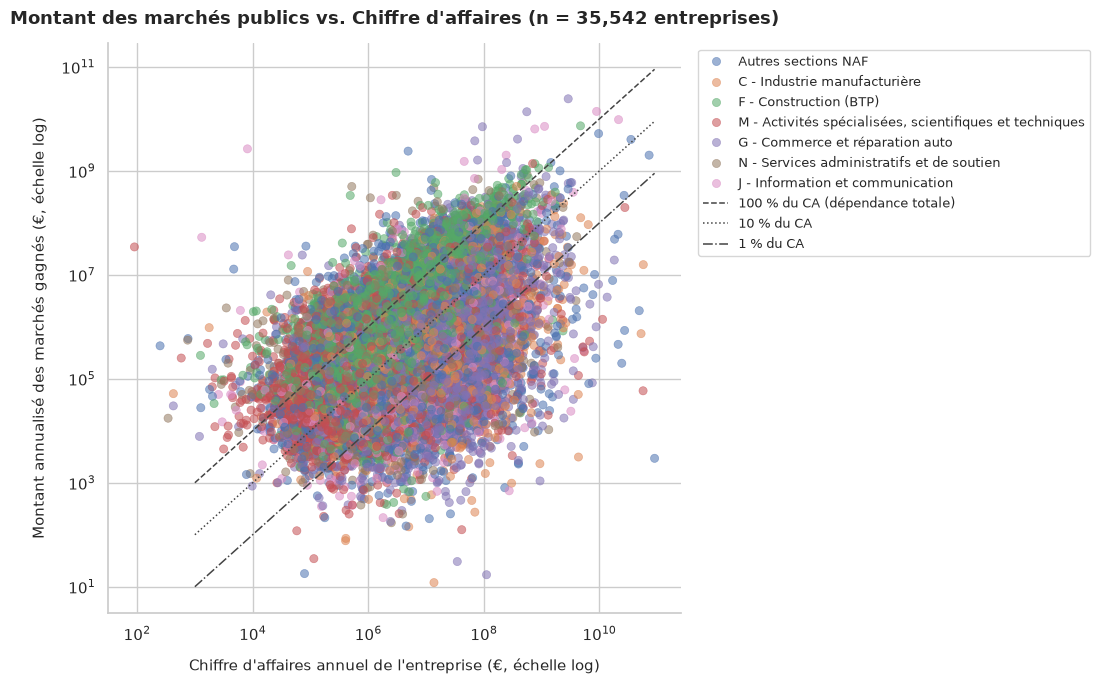

Médiane du ratio (Montant annualisé / CA) : 16.55 %
Part des entreprises réalisant > 10 % de leur CA via la commande publique : 58.8%


In [13]:
from src.inpi_stats_desc import plot_dependance_ca, plot_dependance_secteur

# Graphique 7 : Nuage de points log-log (Montant annualisé des marchés vs Chiffre d'affaires)
plot_dependance_ca(df_entreprise)

Les indicateurs confirment le rôle économique structurant de la commande publique pour les entreprises qui y répondent :

- **Médiane du ratio `Montant annualisé / Chiffre d'affaires` : 16,55 %.** Pour la moitié des entreprises titulaires observables, les marchés publics représentent au moins un sixième de leur chiffre d'affaires annuel.
- **Part des entreprises dépassant 10 % de leur CA via la commande publique : 58,8 %.** Loin d'être un débouché marginal, la commande publique constitue un pilier d'activité pour près de six titulaires sur dix.
- **Une relation croissante mais fortement dispersée :** si les montants remportés croissent logiquement avec la taille en chiffre d'affaires, l'écart vertical à CA donné montre des profils très hétérogènes, allant d'une exposition marginale (< 1 %) à une quasi-exclusivité publique.

### C. Profils de dépendance par secteur d'activité et précautions méthodologiques

Nous découpons enfin les **35 523 entreprises** observables (CA > 0, montant annualisé > 0, NAF renseigné) en trois tranches autour des seuils de **1 %** et **100 %** du chiffre d'affaires, et comparons les **effectifs bruts** et les **parts relatives** par section NAF.

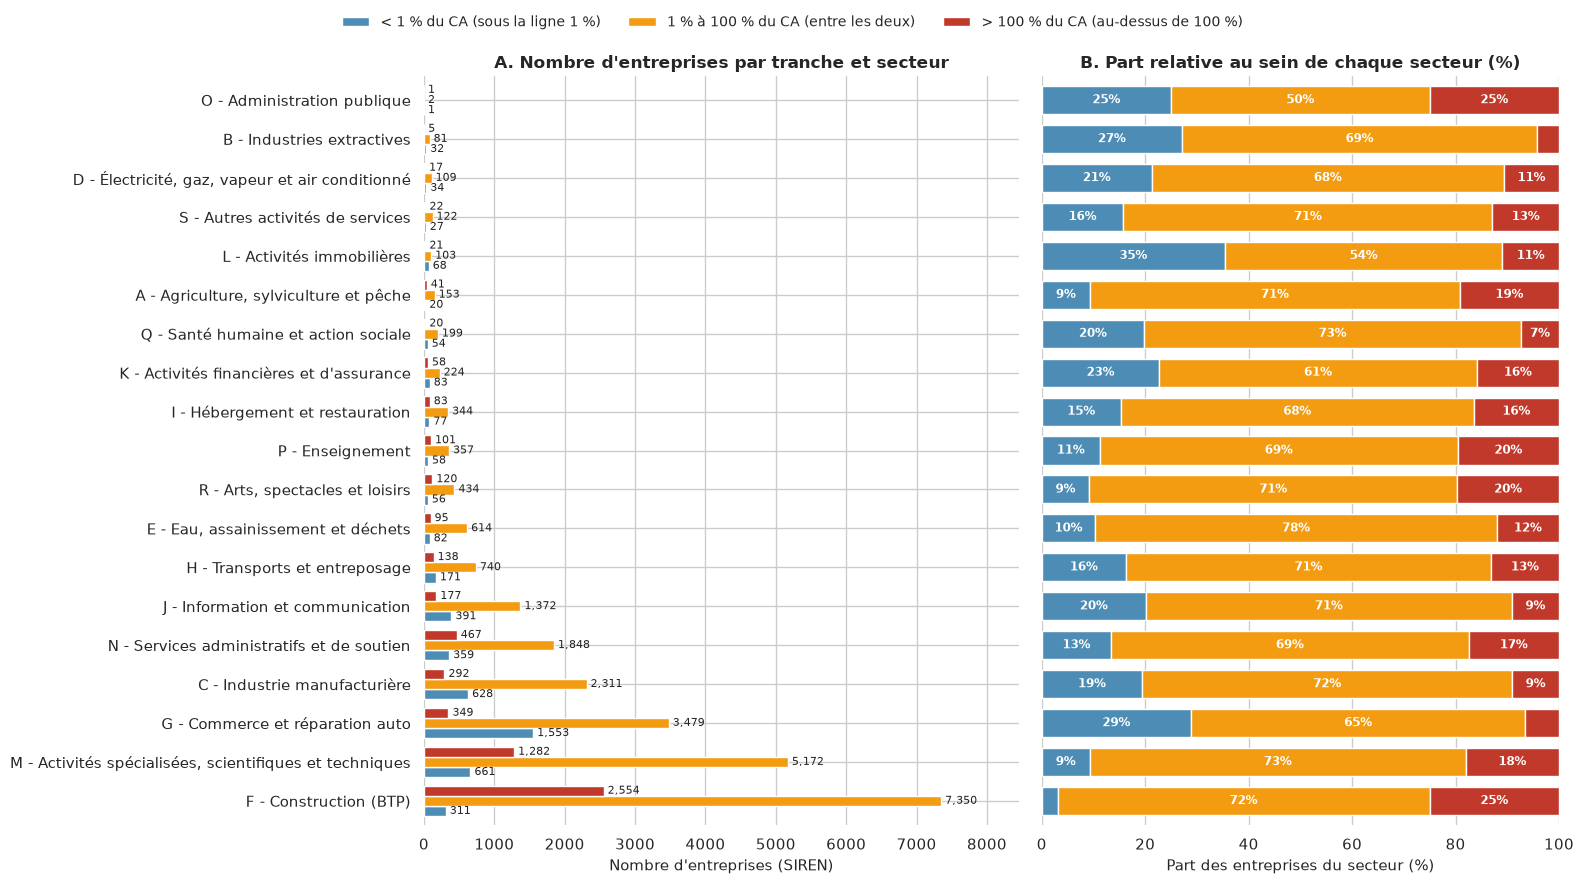

=== RÉPARTITION GLOBALE PAR TRANCHE DE DÉPENDANCE ===
                                    nb_entreprises  part_pct
tranche_dependance                                          
< 1 % du CA (sous la ligne 1 %)               4666      13.1
1 % à 100 % du CA (entre les deux)           25014      70.4
> 100 % du CA (au-dessus de 100 %)            5843      16.4


In [14]:
# Graphique 8 : Répartition par tranche de dépendance (< 1 %, 1-100 %, > 100 % du CA) par section NAF
resume_tranches = plot_dependance_secteur(df_entreprise)

Au niveau global, la répartition des **35 523 entreprises** par tranche de dépendance confirme l'importance du débouché public :

| Tranche de dépendance (`Montant annualisé / CA`) | Nombre d'entreprises | Part (%) |
| :--- | :---: | :---: |
| **< 1 % du CA** (exposition marginale) | 4 666 | **13,1 %** |
| **1 % à 100 % du CA** (dépendance modérée à forte) | 25 014 | **70,4 %** |
| **> 100 % du CA** (montant annualisé supérieur au dernier CA connu) | 5 843 | **16,4 %** |
| **Total analysé** | **35 523** | **100,0 %** |

Plus de sept entreprises sur dix (**70,4 %**) se situent dans la bande cohérente entre 1 % et 100 % de leur chiffre d'affaires, contre seulement **13,1 %** en dessous de 1 %. Le graphique sectoriel confirme par ailleurs la concentration du nombre d'entreprises fortement exposées dans la **Construction (F)**, les **Activités spécialisées (M)** et le **Commerce (G)**.

La présence de **16,4 % d'entreprises au-dessus du seuil de 100 % du CA** (5 843 sociétés) appelle **trois précautions méthodologiques essentielles** :

1. **Effet « plafond d'accord-cadre » :** dans les DECP, les accords-cadres à bons de commande sont publiés pour leur montant *maximal* autorisé, qui est rarement consommé à 100 % dans la réalité — ce qui gonfle mécaniquement `montant_annualise_total`.
2. **Décalage temporel et croissance rapide :** le dernier bilan disponible dans la base INPI/BCE peut précéder de 1 à 3 ans les contrats notifiés en 2024–2026 ; une entreprise jeune ou en forte croissance peut donc remporter des marchés supérieurs à son dernier CA publié.
3. **Sous-traitance et co-traitance :** les montants DECP incluent la part éventuellement sous-traitée, et les groupements sont divisés à parts égales faute de clé contractuelle dans les données brutes.

## IV. Modélisation et pistes d'approfondissement (optionnel)

Dans le cadre de cette étude, la modélisation n'est pas une fin prédictive en soi mais un prolongement analytique destiné à démêler des effets fortement corrélés entre eux (secteur NAF, taille d'établissement, procédure de passation, localisation et taille financière de l'entreprise).

Deux pistes économétriques directement exploitables à partir des tables `df_final` et `df_entreprise` se dégagent :

1. **Isoler l'effet propre du secteur sur le montant des marchés :** une régression linéaire en logarithme,
$$\log(\text{montant\_annualise}_i) = \beta_0 + \beta_{\text{NAF}} + \beta_{\text{taille}} + \beta_{\text{procedure}} + \beta_{\text{dep}} + \varepsilon_i$$
permettrait de distinguer, « toutes choses égales par ailleurs », ce qui relève de la nature intrinsèque d'un secteur (ex. Énergie ou Eau) de ce qui provient simplement de la taille des entreprises titulaires ou du recours à l'appel d'offres ouvert.
2. **Relier dépendance à la commande publique et santé financière :** à partir de `df_entreprise` (où figurent déjà `marge_ebe`, `taux_d_endettement`, `autonomie_financiere` et `credit_clients_jours`), on pourrait tester si les entreprises fortement dépendantes de l'acheteur public affichent, à secteur et chiffre d'affaires comparables, une rentabilité plus stable, un endettement moindre ou des délais de paiement clients spécifiques.

## Conclusion

Nous avons construit ce projet pour répondre de façon empirique et reproductible à une question centrale d'économie publique : **qui bénéficie réellement de la commande publique française, et dans quelle mesure les entreprises titulaires en dépendent-elles ?** En consolidant **923 514 lignes brutes** des DECP (2024–2026), en les nettoyant jusqu'à obtenir **712 959 contrats × titulaires** appariés à **99,7 % en lignes (99,5 % en montant)** au répertoire **Sirene** (44,5 millions d'établissements, dont 16,92 millions d'actifs), puis en croisant les **101 468 entreprises uniques (SIREN)** avec les comptes annuels **INPI / BCE** (**66 170 entreprises appariées**, soit **65,2 %**), nous avons pu dresser un portrait complet de la dépense publique.

Nos analyses apportent trois réponses claires à la problématique :

1. **Une surreprésentation sectorielle massive :** sur les ~**661,7 milliards d'euros** appariés, **94,0 %** des montants se concentrent sur 10 sections NAF et **45,8 %** sur le seul duo **Construction (26,11 %, indice 4,30)** – **Commerce (19,70 %, indice 1,78)**. Les déséquilibres les plus spectaculaires touchent les infrastructures et réseaux, notamment l'**Eau, assainissement et déchets (indice 13,32)**, l'**Information et communication (3,10)** et l'**Électricité et gaz (3,07**, concentrés sur **266 entreprises** avec une médiane de **400 000 €**), alors que l'**Immobilier** (23,52 % des établissements actifs en France) reste marginal.
2. **Une structuration nette par taille et par procédure :** si les petites structures remportent une part importante du *nombre* de marchés (notamment en procédure adaptée), les volumes financiers basculent nettement vers les établissements moyens et les ETI dans les procédures formalisées, avec une progression régulière des montants unitaires selon la taille salariale.
3. **Une dépendance financière élevée des titulaires :** parmi les **35 523 entreprises** à chiffre d'affaires public positif, la **médiane du ratio `montant annualisé / CA` atteint 16,55 %**, et **58,8 %** des entreprises réalisent plus de **10 %** de leur chiffre d'affaires via la commande publique (**70,4 %** se situent entre 1 % et 100 % du CA, et **16,4 %** dépassent 100 % sous l'effet des plafonds d'accords-cadres et des décalages d'exercices).

Ces résultats s'accompagnent de limites méthodologiques clairement identifiées : filtrage des contrats antérieurs à 2024 et des montants symboliques ($\le 100$ €) ou extrêmes ($\ge 500$ M€), répartition égalitaire par défaut des groupements de co-titulaires, asymétrie liée aux plafonds d'accords-cadres non entièrement consommés, confidentialité d'environ un tiers des bilans d'entreprises dans l'INPI/BCE, et écart potentiel entre le département juridique du titulaire (`dep_titulaire`) et le lieu réel d'exécution (`lieuExecution_code`).

Deux pistes prolongeraient naturellement ce travail : mesurer la part d'achats véritablement locaux en confrontant `dep_titulaire` et `lieuExecution_code`, et exploiter les ratios de rentabilité (`marge_ebe`) et de trésorerie (`credit_clients_jours`) déjà intégrés dans `df_entreprise` pour évaluer l'impact de la commande publique sur la solidité financière des PME françaises.